<table style="width:100%; border-collapse:collapse; border:2px solid #333333; background:#f7f7f7; color:#111111; font-family:Georgia,serif;">
<tr>
<td style="width:34%; border:1px solid #333333; padding:16px 20px; vertical-align:middle; text-align:left;">
<span style="font-size:18px;"><b>MADHUR BHAIYA</b></span><br>
<span style="font-size:16px;">BITS ID : <b>2026AJ05066</b></span><br>
</td>
<td style="width:30%; border:1px solid #333333; padding:16px 20px; vertical-align:middle; text-align:center;">
<span style="font-size:24px; letter-spacing:2px;"><b>ASSIGNMENT&nbsp;2</b></span><br>
<span style="font-size:18px; letter-spacing:2px;"><u>QSAR Biodegradation Classification</u></span><br>
</td>
<td style="width:36%; border:1px solid #333333; padding:16px 20px; vertical-align:middle; text-align:right;">
<span style="font-size:18px;"><b>Machine Learning</b></span><br>
<span style="font-size:16px;">Course Code : <b>AIMLZG565</b></span><br>
</td>
</tr>
</table>

### Setup
 - Import numpy and pandas for data analysis
 - Import pathlib, shutil, urllib.request for fetching data file if not available locally

In [1]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import shutil
import urllib.request
import sklearn
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, matthews_corrcoef
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import joblib


# Ensure that the appropriate packages are installed
print("python  ", sys.version.split()[0])
print("numpy   ", np.__version__)
print("pandas  ", pd.__version__)
print("sklearn  ", sklearn.__version__)

python   3.14.4
numpy    2.5.2
pandas   3.0.5
sklearn   1.9.0


### Import Data

In [2]:
# Define data source and path to store in, if not available
DATA_SOURCE_URL = "https://archive.ics.uci.edu/static/public/254/qsar+biodegradation.zip"
DATA_PATH = "data/qsar+biodegradation.zip"

# Column names and descriptions for the UCI QSAR Biodegradation dataset.
# Data (csv) does not contain column headers. These are copied from UCI Website.
# Ref: https://archive.ics.uci.edu/dataset/254/qsar+biodegradation
COLUMN_DESCRIPTIONS = {
    "SpMax_L": "Leading eigenvalue from Laplace matrix",
    "J_Dz(e)": "Balaban-like index from Barysz matrix weighted by Sanderson electronegativity",
    "nHM": "Number of heavy atoms",
    "F01[N-N]": "Frequency of N-N at topological distance 1",
    "F04[C-N]": "Frequency of C-N at topological distance 4",
    "NssssC": "Number of atoms of type ssssC",
    "nCb-": "Number of substituted benzene C(sp2)",
    "C%": "Percentage of C atoms",
    "nCp": "Number of terminal primary C(sp3)",
    "nO": "Number of oxygen atoms",
    "F03[C-N]": "Frequency of C-N at topological distance 3",
    "SdssC": "Sum of dssC E-states",
    "HyWi_B(m)": "Hyper-Wiener-like index (log function) from Burden matrix weighted by mass",
    "LOC": "Lopping centric index",
    "SM6_L": "Spectral moment of order 6 from Laplace matrix",
    "F03[C-O]": "Frequency of C - O at topological distance 3",
    "Me": "Mean atomic Sanderson electronegativity (scaled on Carbon atom)",
    "Mi": "Mean first ionization potential (scaled on Carbon atom)",
    "nN-N": "Number of N hydrazines",
    "nArNO2": "Number of nitro groups (aromatic)",
    "nCRX3": "Number of CRX3",
    "SpPosA_B(p)": "Normalized spectral positive sum from Burden matrix weighted by polarizability",
    "nCIR": "Number of circuits",
    "B01[C-Br]": "Presence/absence of C - Br at topological distance 1",
    "B03[C-Cl]": "Presence/absence of C - Cl at topological distance 3",
    "N-073": "Ar2NH / Ar3N / Ar2N-Al / R..N..R",
    "SpMax_A": "Leading eigenvalue from adjacency matrix (Lovasz-Pelikan index)",
    "Psi_i_1d": "Intrinsic state pseudoconnectivity index - type 1d",
    "B04[C-Br]": "Presence/absence of C - Br at topological distance 4",
    "SdO": "Sum of dO E-states",
    "TI2_L": "Second Mohar index from Laplace matrix",
    "nCrt": "Number of ring tertiary C(sp3)",
    "C-026": "R--CX--R",
    "F02[C-N]": "Frequency of C - N at topological distance 2",
    "nHDon": "Number of donor atoms for H-bonds (N and O)",
    "SpMax_B(m)": "Leading eigenvalue from Burden matrix weighted by mass",
    "Psi_i_A": "Intrinsic state pseudoconnectivity index - type S average",
    "nN": "Number of Nitrogen atoms",
    "SM6_B(m)": "Spectral moment of order 6 from Burden matrix weighted by mass",
    "nArCOOR": "Number of esters (aromatic)",
    "nX": "Number of halogen atoms",
    "experimental_class": "Ready biodegradable (RB) or not ready biodegradable (NRB)",
}

# Same order as the columns in the data.csv: 41 features, then the label.
COLUMN_NAMES = list(COLUMN_DESCRIPTIONS)
TARGET_COLUMN = "experimental_class"
FEATURE_NAMES = [c for c in COLUMN_NAMES if c != TARGET_COLUMN]

df = None

# If data is not available on the path, then fetch it from Source URL
dp = Path(DATA_PATH) 
if not dp.is_file():
    print(f"Data file not found at {dp}. Downloading...")

    # Ensure parent directory exists
    dp.parent.mkdir(parents=True, exist_ok=True)

    # Do HTTP Request, and copy file to the DATA_PATH
    req = urllib.request.Request(DATA_SOURCE_URL)
    with urllib.request.urlopen(req) as response, open(dp, "wb") as out_file:
        shutil.copyfileobj(response, out_file)

# load into dataframe. pandas handles decompression automatically
print(f"Loading datafile at {dp} into dataframe...")
df = pd.read_csv(DATA_PATH, sep=';', header=None, names=COLUMN_NAMES)

print(df)



Loading datafile at data/qsar+biodegradation.zip into dataframe...
      SpMax_L  J_Dz(e)  nHM  F01[N-N]  F04[C-N]  NssssC  nCb-    C%  nCp  nO  \
0       3.919   2.6909    0         0         0       0     0  31.4    2   0   
1       4.170   2.1144    0         0         0       0     0  30.8    1   1   
2       3.932   3.2512    0         0         0       0     0  26.7    2   4   
3       3.000   2.7098    0         0         0       0     0  20.0    0   2   
4       4.236   3.3944    0         0         0       0     0  29.4    2   4   
...       ...      ...  ...       ...       ...     ...   ...   ...  ...  ..   
1050    5.431   2.8955    0         0         0       2     0  32.1    4   1   
1051    5.287   3.3732    0         0         9       0     0  35.3    0   9   
1052    4.869   1.7670    0         1         9       0     5  44.4    0   4   
1053    5.158   1.6914    2         0        36       0     9  56.1    0   0   
1054    5.076   2.6588    2         0         0      

---
---
### Exploratory Data Analysis

In [3]:
# Check the shape (sample count = total number of rows, number of features = total number of columns - 1)
# Last column is of target class
print(f"Data sample count: {df.shape[0]}, Feature count:{df.shape[1] - 1}")
print(f"Printing dataframe info...")
df.info()

Data sample count: 1055, Feature count:41
Printing dataframe info...
<class 'pandas.DataFrame'>
RangeIndex: 1055 entries, 0 to 1054
Data columns (total 42 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   SpMax_L             1055 non-null   float64
 1   J_Dz(e)             1055 non-null   float64
 2   nHM                 1055 non-null   int64  
 3   F01[N-N]            1055 non-null   int64  
 4   F04[C-N]            1055 non-null   int64  
 5   NssssC              1055 non-null   int64  
 6   nCb-                1055 non-null   int64  
 7   C%                  1055 non-null   float64
 8   nCp                 1055 non-null   int64  
 9   nO                  1055 non-null   int64  
 10  F03[C-N]            1055 non-null   int64  
 11  SdssC               1055 non-null   float64
 12  HyWi_B(m)           1055 non-null   float64
 13  LOC                 1055 non-null   float64
 14  SM6_L               1055 non-null   float64
 1

In [4]:
# Check if there are any missing values
found_null = False
for column, count in df.isnull().sum().items():
    if count > 0:
        found_null = True
        print(f"Feature '{column}' has {count} missing value(s).")
if not found_null:
    print(f"There are no features with missing values.")

There are no features with missing values.


In [5]:
# Check if any samples are duplicated
duplicated_samples = df.duplicated().sum()
if duplicated_samples > 0:
    print(f"There are {duplicated_samples} duplicated samples found in the data.")
else:
    print(f"There are no duplicated samples in the data.")

There are 3 duplicated samples found in the data.


In [6]:
# Check class balance - will be needed to find sampling technique to be used
# We will get counts and proportions for the target column only
display(
    pd.concat([df[TARGET_COLUMN].value_counts(), df[TARGET_COLUMN].value_counts(normalize=True)],
    axis=1)
)

,count,proportion
experimental_class,,
NRB,699,0.662559
RB,356,0.337441


In [7]:
# Check feature wise statistics to determine if we need normalization/standardization
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SpMax_L,1055.0,4.782644,0.546916,2.0000,4.48100,4.8280,5.12500,6.4960
J_Dz(e),1055.0,3.069508,0.831308,0.8039,2.50275,3.0463,3.43765,9.1775
nHM,1055.0,0.716588,1.462452,0.0000,0.00000,0.0000,1.00000,12.0000
F01[N-N],1055.0,0.042654,0.256010,0.0000,0.00000,0.0000,0.00000,3.0000
F04[C-N],1055.0,0.980095,2.332955,0.0000,0.00000,0.0000,1.00000,36.0000
NssssC,1055.0,0.290047,1.073771,0.0000,0.00000,0.0000,0.00000,13.0000
nCb-,1055.0,1.646445,2.224822,0.0000,0.00000,1.0000,3.00000,18.0000
C%,1055.0,37.055640,9.144466,0.0000,30.45000,37.5000,43.40000,60.7000
nCp,1055.0,1.376303,1.963521,0.0000,0.00000,1.0000,2.00000,24.0000
nO,1055.0,1.803791,1.775435,0.0000,0.00000,2.0000,3.00000,12.0000


In [8]:
# Check count of unique values feature wise
unq_vals_feature_wise = df[FEATURE_NAMES].nunique()
display(unq_vals_feature_wise)

# Find out the features with binary values (number of unique values = 2)
binary_features = unq_vals_feature_wise.index[unq_vals_feature_wise == 2].to_list()
print(f"Total number of binary features (features with only two possible values) are: {len(binary_features)}")
print(f"Binary features are: {binary_features}")

# Find out how many features are mostly zeros (> 80%)
zeros_feature_wise = (df[FEATURE_NAMES] == 0).mean()
more_than_80pct_zeros_features = zeros_feature_wise.index[zeros_feature_wise > 0.8].to_list()
print(f"Total number of features with > 80% zeros are: {len(more_than_80pct_zeros_features)}")
print(f"Features with > 80% zeros are: {more_than_80pct_zeros_features}")


SpMax_L         440
J_Dz(e)        1022
nHM              11
F01[N-N]          4
F04[C-N]         16
NssssC           13
nCb-             15
C%              188
nCp              15
nO               12
F03[C-N]         21
SdssC           384
HyWi_B(m)       756
LOC             373
SM6_L           510
F03[C-O]         24
Me              167
Mi              125
nN-N              3
nArNO2            4
nCRX3             4
SpPosA_B(p)     352
nCIR             13
B01[C-Br]         2
B03[C-Cl]         2
N-073             4
SpMax_A         329
Psi_i_1d        205
B04[C-Br]         2
SdO             470
TI2_L           553
nCrt              8
C-026            11
F02[C-N]         16
nHDon             8
SpMax_B(m)      705
Psi_i_A         624
nN                8
SM6_B(m)        862
nArCOOR           5
nX               17
dtype: int64

Total number of binary features (features with only two possible values) are: 3
Binary features are: ['B01[C-Br]', 'B03[C-Cl]', 'B04[C-Br]']
Total number of features with > 80% zeros are: 11
Features with > 80% zeros are: ['F01[N-N]', 'NssssC', 'nN-N', 'nArNO2', 'nCRX3', 'B01[C-Br]', 'B03[C-Cl]', 'N-073', 'B04[C-Br]', 'nCrt', 'nArCOOR']


#### Summary of EDA findings

| Aspect | Finding | What it means for modelling |
|---|---|---|
| Size | 1,055 samples, 41 features + 1 target (`experimental_class`) | More than 500 samples and 12 features |
| Feature types | All 41 features are numeric: 17 continuous descriptors and 24 integer-valued. Of the integer ones, 3 are binary presence/absence flags (`binary_features`: `B01[C-Br]`, `B03[C-Cl]`, `B04[C-Br]`) and 21 are counts/frequencies (e.g. `nHM`, `nO`, `F03[C-O]`) | No categorical encoding needed |
| Missing values | None in any column | No imputation needed |
| Duplicates | 3 exact duplicate rows (`duplicated_samples`), each with the same label | Needs to be dropped before the train/test split so the same molecule cannot land in both sets (1,052 rows remain) |
| Class balance | NRB = 699 (66.3%), RB = 356 (33.7%), roughly 2 : 1 | Mild imbalance: We can use a stratified split, and judge models on F1, AUC and MCC, not accuracy alone |
| Feature scales | Ranges differ widely, e.g. `Me` spans 0.957 to 1.311 (std 0.046) while `C%` spans 0 to 60.7 and `nCIR` goes up to 147 | Scale features for Logistic Regression, KNN and SVM; Decision Tree does not need it |
| Sparsity and skew | 11 of 41 features are zero in more than 80% of rows; count features are right-skewed (e.g. `nCIR`: 75th percentile = 2, max = 147) | Outliers are expected; distance-based KNN is the most sensitive to them |
| Negative values | `SdssC` (min -5.256) and `Psi_i_1d` (min -1.099) contain negative values | Multinomial Naive Bayes needs non-negative inputs, so **Gaussian Naive Bayes** is the right choice here |

---
---
### Data Preparation

In [9]:
# Cleanup the duplicates
df_cleaned = df.drop_duplicates()
print(f"Original count of samples: {len(df)}")
print(f"Count of samples after duplicates removal: {len(df_cleaned)}")

# Measure new class imbalance
display(
    pd.concat([df_cleaned[TARGET_COLUMN].value_counts(), df_cleaned[TARGET_COLUMN].value_counts(normalize=True)],
    axis=1)
)

Original count of samples: 1055
Count of samples after duplicates removal: 1052


,count,proportion
experimental_class,,
NRB,698,0.663498
RB,354,0.336502


In [10]:
# Separate the inputs (X) and target (y)
X = df_cleaned[FEATURE_NAMES]
y = df_cleaned[TARGET_COLUMN]

#### Train - Test Split and Save Test Data

In [11]:
# We will do 80-20 split (80% training data and 20% test data)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=552, stratify=y
)

print("Training Data: ")
display(pd.concat([X_train, y_train], axis = 1))
print("Test Data: ")
display(pd.concat([X_test, y_test], axis = 1))

# Saving test_data.csv
pd.concat([X_test, y_test], axis=1).to_csv('test_data.csv', index=False)

Training Data: 


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,experimental_class
464,4.961,2.4328,2,0,0,0,6,48.1,0,2,...,4,0,2,3.939,2.572,0,9.249,0,2,NRB
691,4.802,1.7012,4,0,4,0,4,50.0,0,0,...,0,4,0,4.462,1.967,2,9.901,0,0,NRB
134,4.588,4.0275,0,0,0,0,0,32.0,3,3,...,0,0,0,3.480,2.833,0,8.066,0,0,RB
634,4.739,2.1754,0,0,3,0,3,42.9,2,0,...,3,8,2,3.688,1.961,2,8.671,0,0,NRB
277,4.170,2.9651,0,0,0,0,0,33.3,2,0,...,0,1,0,3.330,2.767,1,7.322,0,0,RB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
146,4.770,2.8938,0,0,0,0,2,41.7,3,0,...,0,0,0,3.646,1.867,0,8.083,0,0,RB
625,5.333,4.7127,0,0,0,2,0,27.9,6,5,...,0,0,4,3.386,2.706,0,8.143,0,0,NRB
481,5.000,2.0390,0,0,0,0,0,45.5,0,0,...,0,0,0,3.633,1.633,0,8.066,0,0,NRB
274,4.334,3.6944,0,0,0,0,0,33.3,1,2,...,0,0,0,3.421,2.952,0,7.598,0,0,RB


Test Data: 


,SpMax_L,J_Dz(e),nHM,F01[N-N],F04[C-N],NssssC,nCb-,C%,nCp,nO,...,C-026,F02[C-N],nHDon,SpMax_B(m),Psi_i_A,nN,SM6_B(m),nArCOOR,nX,experimental_class
53,4.691,3.8787,0,0,0,0,0,25.0,0,4,...,0,2,4,3.483,4.019,1,8.015,0,0,RB
109,3.414,2.1848,0,0,0,0,0,18.2,2,1,...,0,1,3,2.790,3.250,1,6.251,0,0,RB
595,4.214,2.8141,0,0,0,0,0,33.3,2,0,...,0,0,0,3.090,1.972,0,7.038,0,0,NRB
47,4.655,2.4090,0,0,0,0,0,35.0,1,3,...,0,0,0,3.542,2.667,0,8.185,0,0,RB
549,4.500,3.9147,4,0,0,0,0,31.3,3,0,...,0,0,0,4.527,1.552,0,9.639,0,0,NRB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
461,5.114,2.4193,0,0,0,0,4,47.1,3,0,...,0,0,0,3.771,1.875,0,8.682,0,0,NRB
933,4.732,3.1657,0,0,0,0,3,42.9,3,0,...,0,0,0,3.690,1.889,0,8.082,0,0,NRB
208,4.562,3.2113,0,0,0,0,2,42.9,0,2,...,2,0,2,3.646,2.917,0,8.003,0,0,RB
377,4.679,2.8711,0,0,0,0,2,41.7,2,0,...,0,0,0,3.627,1.833,0,8.015,0,0,NRB


---
---
### Training Models

In [12]:
# First, convert the target class to binary (0/1) for both - training and test data
# RB = 1; NRB = 0
TARGET_CLASS_TO_BINARY = {"RB": 1, "NRB": 0}
y_train = y_train.map(TARGET_CLASS_TO_BINARY)
y_test = y_test.map(TARGET_CLASS_TO_BINARY)

# Ensure there are no nulls after map
if y_train.isnull().sum() > 0:
    raise ValueError("Training data has nulls after map")
if y_test.isnull().sum() > 0:
    raise ValueError("Test data has nulls after map")

display(
    pd.concat([y_train.value_counts(), y_train.value_counts(normalize=True)],
    axis=1)
)
display(
    pd.concat([y_test.value_counts(), y_test.value_counts(normalize=True)],
    axis=1)
)

# We will also do Cross-Validation for better generalized models
# Setting up first time, so all training steps can reuse the same
# Since the data has class imbalance, we will use Stratified K Fold Cross Validation
# K = n_splits = 5
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)

# F1 score would be better measure here than accuracy (because of class imbalance)
SCORING_MEASURE = "f1"

# Best (tuned) pipeline of each model is collected here, for evaluation and saving later
best_models = {}

,count,proportion
experimental_class,,
0,558,0.663496
1,283,0.336504


,count,proportion
experimental_class,,
0,140,0.663507
1,71,0.336493


---
### 1. Logistic Regression

In [13]:
# Make pipeline for logistic regression
log_reg_pipe = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=5000, random_state=552)), # Keeping max iterations high because saga solver learns slowly
    ]
)

# Defining parameter grid so that GridSearchCV can find the best parameter combination
# We will try L1, L2 and Elastic net regularization. Since each support different set of parameters / solvers,
# we will use 3 different Grids (dict) for them
# For regularization strength (C), we will try from 0.001 to 100 (log scale).
# Low value of C means high regularization => simpler and generalized model.
# Since target classes are imbalanced, we will try class_weight = None and "balanced"
log_reg_param_grid = [
    {   # Grid 1: L2 with lbfgs
        # Total 1 * 1 * 6 * 2 = 12 combinations
        "classifier__l1_ratio": [0], # l1_ratio = 0 means L2
        "classifier__solver": ["lbfgs"],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"],
    },
    {   # Grid 2: L1 with liblinear
        # Total 1 * 1 * 6 * 2 = 12 combinations
        "classifier__l1_ratio": [1], # l1_ratio = 1 means L1
        "classifier__solver": ["liblinear"],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"],
    },
    {   # Grid 3: ElasticNet with saga (the only solver that supports it)
        # Total 1 * 1 * 3 * 6 * 2 = 36 combinations
        "classifier__l1_ratio": [0.2, 0.5, 0.8], # Elastic Net Ratio (r)
        "classifier__solver": ["saga"],
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__class_weight": [None, "balanced"],
    },
]

# Total combinations = 12 + 12 + 36 = 60 combinations
# Since we are doing 5-fold CV => 60 * 5 = 300 fits

# Setup the Grid Search (brute force approach)
log_reg_grid_search = GridSearchCV(
    estimator=log_reg_pipe,   # the pipeline (scaler + model)
    param_grid=log_reg_param_grid,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,                     # -1 means use all CPU cores
    refit=True,                    # need to retrain best model on full training data (once found)
    verbose=1,                     # print progress
)

# Perform grid search with 5-fold CV on training data
log_reg_grid_search.fit(X_train, y_train)

# Display the top 10 hyperparameter combinations
log_reg_results = pd.DataFrame(log_reg_grid_search.cv_results_)
log_reg_param_cols = [col for col in log_reg_results.columns if col.startswith("param_")]
display(
    log_reg_results[log_reg_param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


,param_classifier__C,param_classifier__class_weight,param_classifier__l1_ratio,param_classifier__solver,mean_test_score,std_test_score,rank_test_score
42,1.0,NaN,0.2,saga,0.799072,0.044267,1
19,1.0,balanced,1.0,liblinear,0.798422,0.028694,2
43,1.0,NaN,0.5,saga,0.798059,0.039126,3
18,1.0,NaN,1.0,liblinear,0.798059,0.039126,3
6,1.0,NaN,0.0,lbfgs,0.797732,0.046763,5
44,1.0,NaN,0.8,saga,0.796681,0.037964,6
46,1.0,balanced,0.5,saga,0.796529,0.030206,7
47,1.0,balanced,0.8,saga,0.796315,0.033100,8
5,0.1,balanced,0.0,lbfgs,0.796079,0.025101,9
39,0.1,balanced,0.2,saga,0.793858,0.020709,10


In [14]:
# Round 2: fine-tune C around 1 (the best value from round 1)
# Round 1 showed that L1, L2 and Elastic Net score almost the same, so only the saga grid
# (which covers the Elastic Net mix) is searched here, to keep the run time low
log_reg_param_grid_fine = {
    "classifier__l1_ratio": [0.2, 0.5, 0.8],
    "classifier__solver": ["saga"],
    "classifier__C": [0.3, 0.5, 0.75, 1, 1.5, 2, 3],
    "classifier__class_weight": [None, "balanced"],
}

# Total combinations = 3 * 1 * 7 * 2 = 42 combinations
# Since we are doing 5-fold CV => 42 * 5 = 210 fits

log_reg_grid_search_fine = GridSearchCV(
    estimator=log_reg_pipe,   # same pipeline (scaler + model) as round 1
    param_grid=log_reg_param_grid_fine,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,
    refit=True,
    verbose=1,
)
log_reg_grid_search_fine.fit(X_train, y_train)

# Display the top 10 combinations, one column per hyperparameter so nothing gets truncated
log_reg_results_fine = pd.DataFrame(log_reg_grid_search_fine.cv_results_)
log_reg_param_cols_fine = [col for col in log_reg_results_fine.columns if col.startswith("param_")]
display(
    log_reg_results_fine[log_reg_param_cols_fine + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

# Keep whichever round found the better CV score
print("Logistic Regression :: Round 1 best params:", log_reg_grid_search.best_params_)
print("Logistic Regression :: Round 1 best CV F1 score:", round(log_reg_grid_search.best_score_, 4))

print("Logistic Regression :: Round 2 best params:", log_reg_grid_search_fine.best_params_)
print("Logistic Regression :: Round 2 best CV F1 score:", round(log_reg_grid_search_fine.best_score_, 4))

if log_reg_grid_search_fine.best_score_ > log_reg_grid_search.best_score_:
    log_reg_search = log_reg_grid_search_fine
else:
    log_reg_search = log_reg_grid_search

# Training score close to the CV score means the model is not overfitting
print("Logistic Regression :: Selected parameters:", log_reg_search.best_params_)
print("Logistic Regression :: Selected CV F1 score:", round(log_reg_search.best_score_, 4))
print("Logistic Regression :: Training F1 score:", round(log_reg_search.score(X_train, y_train), 4))

# best_estimator_ is the whole pipeline (scaler + model), retrained on the full training data
best_models["Logistic Regression"] = log_reg_search.best_estimator_

Fitting 5 folds for each of 42 candidates, totalling 210 fits


,param_classifier__C,param_classifier__class_weight,param_classifier__l1_ratio,param_classifier__solver,mean_test_score,std_test_score,rank_test_score
10,0.50,balanced,0.5,saga,0.802877,0.035083,1
25,1.50,NaN,0.5,saga,0.802321,0.040548,2
17,0.75,balanced,0.8,saga,0.802258,0.036784,3
9,0.50,balanced,0.2,saga,0.801807,0.028695,4
31,2.00,NaN,0.5,saga,0.800776,0.040025,5
26,1.50,NaN,0.8,saga,0.800776,0.040025,5
32,2.00,NaN,0.8,saga,0.800776,0.040025,5
15,0.75,balanced,0.2,saga,0.799435,0.029763,8
5,0.30,balanced,0.8,saga,0.799354,0.032758,9
30,2.00,NaN,0.2,saga,0.799199,0.046112,10


Logistic Regression :: Round 1 best params: {'classifier__C': 1, 'classifier__class_weight': None, 'classifier__l1_ratio': 0.2, 'classifier__solver': 'saga'}
Logistic Regression :: Round 1 best CV F1 score: 0.7991
Logistic Regression :: Round 2 best params: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced', 'classifier__l1_ratio': 0.5, 'classifier__solver': 'saga'}
Logistic Regression :: Round 2 best CV F1 score: 0.8029
Logistic Regression :: Selected parameters: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced', 'classifier__l1_ratio': 0.5, 'classifier__solver': 'saga'}
Logistic Regression :: Selected CV F1 score: 0.8029
Logistic Regression :: Training F1 score: 0.8124


#### Observations: Logistic Regression

| | Round 1 (wide search) | Round 2 (C fine-tune) |
|---|---|---|
| Search | L1 / L2 / Elastic Net, C = 0.001 to 100, class_weight None / balanced: 60 combinations, 300 fits | saga (Elastic Net) only, C = 0.3 to 3, class_weight None / balanced: 42 combinations, 210 fits |
| Best settings | C = 1, l1_ratio = 0.2, class_weight = None | C = 0.5, l1_ratio = 0.5, class_weight = balanced |
| Best CV F1 | 0.7991 | **0.8029** (std 0.035 across folds) |
| Training F1 | 0.8225 | 0.8124 |

- **Type of penalty hardly matters.** Best L2 = 0.7977, best L1 = 0.7984, best Elastic Net = 0.7991. The top 10 combinations of round 1 all lie between 0.794 and 0.799.
- **Too much regularisation hurts.** C = 0.001 gives at best 0.736 and C = 0.01 gives 0.755, because the model is held back so strongly that it underfits. From C = 0.1 upwards all scores are around 0.79 to 0.80, and even C = 100 (almost no regularisation) still gives 0.792. With 841 training rows and 41 features, the plain linear model does not overfit much on its own.
- **class_weight = "balanced" gives no clear gain.** Best balanced = 0.7984 vs best None = 0.7991 in round 1, so the 2 : 1 class imbalance is mild enough for this model.
- **Fine-tuning C gave only +0.004** (0.7991 to 0.8029). That is far inside the noise (std 0.035), so the model is not sensitive to C around 1. Round 2's best is kept because it scored highest, but the two rounds are practically equal.
- **No overfitting.** The selected model's training F1 (0.8124) is only about 0.01 above its CV F1 (0.8029).
- The selected pipeline (StandardScaler + LogisticRegression) is stored in `best_models["Logistic Regression"]`. Its test-set metrics are calculated in the evaluation step.

---
### 2. Decision Tree

In [15]:
# Round 1 - Grow a tree to max depth possible and measure its max depth and leaf nodes
decsn_tree_max_depth = DecisionTreeClassifier(random_state=552)
decsn_tree_max_depth.fit(X_train, y_train)

print(f"Max depth of Decision Tree: {decsn_tree_max_depth.get_depth()}")
print(f"Number of leaf nodes in max depth decision tree: {decsn_tree_max_depth.get_n_leaves()}")



Max depth of Decision Tree: 13
Number of leaf nodes in max depth decision tree: 100


In [16]:
# Round 2
# Make pipeline for Decision Tree
decsn_tree_pipe = Pipeline(
    steps=[
        # Decision Tree does not need any scaling
        ("classifier", DecisionTreeClassifier(random_state=552))
    ]
)

# Defining parameter grid so that GridSearchCV can find the best parameter combination
decsn_tree_param_grid = [
    {   # Total 2 * 5 * 5 * 2 = 100 combinations
        "classifier__criterion": ["gini", "entropy"],
        "classifier__max_depth": [None, 5, 7, 10, 13], # max depth = 13 in previous round
        "classifier__min_samples_leaf": [1,3,5,7,10],
        "classifier__class_weight": [None, "balanced"],
    }
]

# Total combinations = 100 combinations
# Since we are doing 5-fold CV => 100 * 5 = 500 fits

# Setup the Grid Search (brute force approach)
decsn_tree_grid_search = GridSearchCV(
    estimator=decsn_tree_pipe,     # the pipeline
    param_grid=decsn_tree_param_grid,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,                     # -1 means use all CPU cores
    refit=True,                    # need to retrain best model on full training data (once found)
    verbose=1,                     # print progress
)

# Perform grid search with 5-fold CV on training data
decsn_tree_grid_search.fit(X_train, y_train)

# Display the top 10 hyperparameter combinations
decsn_tree_results = pd.DataFrame(decsn_tree_grid_search.cv_results_)
decsn_tree_param_cols = [col for col in decsn_tree_results.columns if col.startswith("param_")]
display(
    decsn_tree_results[decsn_tree_param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,param_classifier__class_weight,param_classifier__criterion,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
61,balanced,gini,7,3,0.749361,0.033550,1
62,balanced,gini,7,5,0.741925,0.027904,2
60,balanced,gini,7,1,0.740335,0.040333,3
51,balanced,gini,None,3,0.739591,0.043565,4
66,balanced,gini,10,3,0.735642,0.036654,5
65,balanced,gini,10,1,0.735209,0.031024,6
71,balanced,gini,13,3,0.734583,0.051016,7
52,balanced,gini,None,5,0.733676,0.028055,8
72,balanced,gini,13,5,0.733676,0.028055,8
67,balanced,gini,10,5,0.733478,0.030120,10


In [17]:
# Round 3: fine-tune max_depth around 7, and min_samples_leaf around 1 and 3 (top 10 has both values)
# Round 2 showed that top 5 results have max_depth = 7 and min_samples_leaf = 3
# Round 2 showed that all top 10 results are gini only. So, we will use gini only for fine tuning
decsn_tree_param_grid_fine = [
    {   # Total 1 * 4 * 4 * 1 = 16 combinations
        "classifier__criterion": ["gini"],
        "classifier__max_depth": [6,7,8,9], # max depth = 5 and 10 were already tested in previous round
        "classifier__min_samples_leaf": [1,2,3,4],
        "classifier__class_weight": ["balanced"], # top 10 results were balanced only
    }
]

# Total combinations = 16 combinations
# Since we are doing 5-fold CV => 16 * 5 = 80 fits

decsn_tree_grid_search_fine = GridSearchCV(
    estimator=decsn_tree_pipe,   # same pipeline as round 2
    param_grid=decsn_tree_param_grid_fine,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,
    refit=True,
    verbose=1,
)
decsn_tree_grid_search_fine.fit(X_train, y_train)

# Display the top 10 combinations, one column per hyperparameter so nothing gets truncated
decsn_tree_results_fine = pd.DataFrame(decsn_tree_grid_search_fine.cv_results_)
decsn_tree_param_cols_fine = [col for col in decsn_tree_results_fine.columns if col.startswith("param_")]
display(
    decsn_tree_results_fine[decsn_tree_param_cols_fine + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

# Keep whichever round found the better CV score
print("Decision Tree :: Round 2 best params:", decsn_tree_grid_search.best_params_)
print("Decision Tree :: Round 2 best CV F1 score:", round(decsn_tree_grid_search.best_score_, 4))

print("Decision Tree :: Round 3 best params:", decsn_tree_grid_search_fine.best_params_)
print("Decision Tree :: Round 3 best CV F1 score:", round(decsn_tree_grid_search_fine.best_score_, 4))

if decsn_tree_grid_search_fine.best_score_ > decsn_tree_grid_search.best_score_:
    decsn_tree_search = decsn_tree_grid_search_fine
else:
    decsn_tree_search = decsn_tree_grid_search

# Training score close to the CV score means the model is not overfitting
print("Decision Tree :: Selected parameters:", decsn_tree_search.best_params_)
print("Decision Tree :: Selected CV F1 score:", round(decsn_tree_search.best_score_, 4))
print("Decision Tree :: Training F1 score:", round(decsn_tree_search.score(X_train, y_train), 4))

# best_estimator_ is the whole pipeline, retrained on the full training data
best_models["Decision Tree"] = decsn_tree_search.best_estimator_

Fitting 5 folds for each of 16 candidates, totalling 80 fits


,param_classifier__class_weight,param_classifier__criterion,param_classifier__max_depth,param_classifier__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
6,balanced,gini,7,3,0.749361,0.033550,1
7,balanced,gini,7,4,0.747004,0.028783,2
11,balanced,gini,8,4,0.744546,0.031666,3
14,balanced,gini,9,3,0.742558,0.037255,4
5,balanced,gini,7,2,0.741698,0.040463,5
4,balanced,gini,7,1,0.740335,0.040333,6
2,balanced,gini,6,3,0.739547,0.033964,7
3,balanced,gini,6,4,0.739228,0.027622,8
15,balanced,gini,9,4,0.738195,0.035888,9
10,balanced,gini,8,3,0.737128,0.046773,10


Decision Tree :: Round 2 best params: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 3}
Decision Tree :: Round 2 best CV F1 score: 0.7494
Decision Tree :: Round 3 best params: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 3}
Decision Tree :: Round 3 best CV F1 score: 0.7494
Decision Tree :: Selected parameters: {'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 7, 'classifier__min_samples_leaf': 3}
Decision Tree :: Selected CV F1 score: 0.7494
Decision Tree :: Training F1 score: 0.8651


#### Observations: Decision Tree

- A tree with no limits grew to depth 13 with 100 leaf nodes, so depths between 5 and 13 (and None) were tried in round 2.
- Best settings: max_depth = 7, min_samples_leaf = 3, criterion = gini, class_weight = balanced. Best CV F1 = 0.7494.
- Round 3 (depth 6 to 9, leaf 1 to 4) did not find anything better. Depth 7 with leaf 3 stayed on top.
- All top 10 results used class_weight = balanced and gini. So for the tree, giving more weight to the smaller RB class helps. This was not the case for Logistic Regression.
- Training F1 is 0.8651 but CV F1 is 0.7494, a gap of about 0.12. The tree is learning some of the training data by heart (overfitting). For Logistic Regression this gap was only about 0.01.
- CV F1 of the Decision Tree (0.7494) is lower than Logistic Regression (0.8029).

---
### 3. kNN (k Nearest Neighbour)

In [18]:
# Make pipeline for k Nearest Neighbour
knn_pipe = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier()),
    ]
)

# Defining parameter grid so that GridSearchCV can find the best parameter combination
# By thumbrule, k = sqrt(N) = sqrt(841) = 29. We will try odd values from 1 to 59 (29 being mid point roughly)
knn_param_grid = [
    {
        "classifier__n_neighbors": list(range(1, 61, 2)), # range never considers the last element
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2], # Distance metric; 1 = Manhattan; 2 = Euclidean
    },
]

# Total combinations = 30 * 2 * 2 = 120 combinations
# Since we are doing 5-fold CV => 120 * 5 = 600 fits

# Setup the Grid Search (brute force approach)
knn_grid_search = GridSearchCV(
    estimator=knn_pipe,   # the pipeline (scaler + model)
    param_grid=knn_param_grid,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,                     # -1 means use all CPU cores
    refit=True,                    # need to retrain best model on full training data (once found)
    verbose=1,                     # print progress
)

# Perform grid search with 5-fold CV on training data
knn_grid_search.fit(X_train, y_train)

# Display the top 10 hyperparameter combinations
knn_results = pd.DataFrame(knn_grid_search.cv_results_)
knn_param_cols = [col for col in knn_results.columns if col.startswith("param_")]
display(
    knn_results[knn_param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

# We dont need further fine tuning for kNN, as we have already tried all odd values from 1 to 59
# Top 10 results have majority of Manhattan distance as metric (p = 1), and majority of distance based weights.

print("kNN :: Selected parameters:", knn_grid_search.best_params_)
print("kNN :: Selected CV F1 score:", round(knn_grid_search.best_score_, 4))
print("kNN :: Training F1 score:", round(knn_grid_search.score(X_train, y_train), 4))

# best_estimator_ is the whole pipeline, retrained on the full training data
best_models["kNN"] = knn_grid_search.best_estimator_

Fitting 5 folds for each of 120 candidates, totalling 600 fits


,param_classifier__n_neighbors,param_classifier__p,param_classifier__weights,mean_test_score,std_test_score,rank_test_score
33,17,1,distance,0.792849,0.025829,1
29,15,1,distance,0.789716,0.025818,2
8,5,1,uniform,0.787784,0.028426,3
17,9,1,distance,0.786453,0.012760,4
16,9,1,uniform,0.785867,0.028479,5
21,11,1,distance,0.785252,0.031965,6
25,13,1,distance,0.785249,0.027552,7
9,5,1,distance,0.782018,0.033083,8
47,23,2,distance,0.781731,0.023727,9
5,3,1,distance,0.780059,0.037194,10


kNN :: Selected parameters: {'classifier__n_neighbors': 17, 'classifier__p': 1, 'classifier__weights': 'distance'}
kNN :: Selected CV F1 score: 0.7928
kNN :: Training F1 score: 1.0


#### Observations: kNN

- Odd k values from 1 to 59 were tried, with weights = uniform / distance and p = 1 (Manhattan) / 2 (Euclidean). 120 combinations in total.
- Best settings: k = 17, p = 1, weights = distance. Best CV F1 = 0.7928.
- No round 2 was done. k can only be a whole number, and all odd values in this range were already tried.
- All top 10 results used k between 3 and 23, and their scores are close (0.780 to 0.793). So the exact value of k does not matter much in this range.
- 9 of the top 10 used p = 1 (Manhattan). The best Euclidean (p = 2) result was 0.7817, a little lower.
- Training F1 is 1.0. This is because of weights = distance: each training molecule is its own nearest neighbour (distance 0), so it always gets its own label back. So here the gap between training F1 and CV F1 does not mean real overfitting.
- CV F1 of kNN (0.7928) is a little lower than Logistic Regression (0.8029) and higher than Decision Tree (0.7494).

---
### 4. SVM (Support Vector Machine)

In [19]:
# Make pipeline for SVM
svm_pipe = Pipeline(
    steps=[
        ("scaler", StandardScaler()),
        ("classifier", SVC()),  # When tested with max_iter=5000, lots of runs failed to converge. So using default -1
    ]
)

# Defining parameter grid so that GridSearchCV can find the best parameter combination
# For regularization parameter (C), we will try from 0.001 to 100 (log scale).
# gamma is not needed for linear. So, running two separate set of combinations
svm_param_grid = [
    {   
        # Total combinations = 6 * 1 * 2 = 12 combinations
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__kernel": ["linear"],
        "classifier__class_weight": [None, "balanced"],
    },
    {   # Total combinations = 6 * 3 * 5 * 2 = 180 combinations
        "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "classifier__kernel": ["poly", "rbf", "sigmoid"],
        "classifier__gamma": ["scale", 0.001, 0.01, 0.1, 1],
        "classifier__class_weight": [None, "balanced"],
    }
]

# Total combinations = 12 + 180 = 192 combinations
# Since we are doing 5-fold CV => 192 * 5 = 960 fits

# Setup the Grid Search (brute force approach)
svm_grid_search = GridSearchCV(
    estimator=svm_pipe,            # the pipeline (scaler + model)
    param_grid=svm_param_grid,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,                     # -1 means use all CPU cores
    refit=True,                    # need to retrain best model on full training data (once found)
    verbose=1,                     # print progress
)

# Perform grid search with 5-fold CV on training data
svm_grid_search.fit(X_train, y_train)

# Display the top 10 hyperparameter combinations
svm_results = pd.DataFrame(svm_grid_search.cv_results_)
svm_param_cols = [col for col in svm_results.columns if col.startswith("param_")]
display(
    svm_results[svm_param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


,param_classifier__C,param_classifier__class_weight,param_classifier__kernel,param_classifier__gamma,mean_test_score,std_test_score,rank_test_score
127,1.0,balanced,rbf,0.1,0.813028,0.013734,1
182,100.0,balanced,sigmoid,0.001,0.809332,0.026079,2
5,0.1,balanced,linear,NaN,0.808029,0.028134,3
184,100.0,balanced,rbf,0.01,0.806347,0.017589,4
148,10.0,balanced,rbf,scale,0.804982,0.016316,5
7,1.0,balanced,linear,NaN,0.801273,0.026429,6
181,100.0,balanced,rbf,0.001,0.800148,0.027579,7
118,1.0,balanced,rbf,scale,0.798852,0.024700,8
133,10.0,NaN,rbf,scale,0.797402,0.017923,9
10,100.0,NaN,linear,NaN,0.796930,0.031156,10


In [20]:
# Round 2: fine-tune C and gamma for rbf (top from round 1)
svm_param_grid_fine = [
    {
        "classifier__C": [0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 2, 3, 4, 5, 6, 7, 8, 9],
        "classifier__kernel": ["rbf"],
        "classifier__gamma": [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1, 0.3, 0.5, 0.7, 0.9],
        "classifier__class_weight": ["balanced"],
    },
]

svm_grid_search_fine = GridSearchCV(
    estimator=svm_pipe,   # same pipeline (scaler + model) as round 1
    param_grid=svm_param_grid_fine,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,
    refit=True,
    verbose=1,
)
svm_grid_search_fine.fit(X_train, y_train)

# Display the top 10 combinations, one column per hyperparameter so nothing gets truncated
svm_results_fine = pd.DataFrame(svm_grid_search_fine.cv_results_)
svm_param_cols_fine = [col for col in svm_results_fine.columns if col.startswith("param_")]
display(
    svm_results_fine[svm_param_cols_fine + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

# Keep whichever round found the better CV score
print("SVM :: Round 1 best params:", svm_grid_search.best_params_)
print("SVM :: Round 1 best CV F1 score:", round(svm_grid_search.best_score_, 4))

print("SVM :: Round 2 best params:", svm_grid_search_fine.best_params_)
print("SVM :: Round 2 best CV F1 score:", round(svm_grid_search_fine.best_score_, 4))

if svm_grid_search_fine.best_score_ > svm_grid_search.best_score_:
    svm_search = svm_grid_search_fine
else:
    svm_search = svm_grid_search

print("SVM :: Selected parameters:", svm_search.best_params_)
print("SVM :: Selected CV F1 score:", round(svm_search.best_score_, 4))
print("SVM :: Training F1 score:", round(svm_search.score(X_train, y_train), 4))

# best_estimator_ is the whole pipeline (scaler + model), retrained on the full training data
best_models["SVM"] = svm_search.best_estimator_

Fitting 5 folds for each of 247 candidates, totalling 1235 fits


,param_classifier__C,param_classifier__class_weight,param_classifier__gamma,param_classifier__kernel,mean_test_score,std_test_score,rank_test_score
158,3.0,balanced,0.04,rbf,0.821465,0.021310,1
171,4.0,balanced,0.04,rbf,0.817676,0.017213,2
195,6.0,balanced,0.02,rbf,0.817122,0.022034,3
159,3.0,balanced,0.05,rbf,0.816955,0.021220,4
59,0.9,balanced,0.09,rbf,0.816766,0.017774,5
46,0.8,balanced,0.09,rbf,0.815869,0.023235,6
147,2.0,balanced,0.06,rbf,0.815452,0.023485,7
72,1.0,balanced,0.09,rbf,0.815312,0.017630,8
161,3.0,balanced,0.07,rbf,0.814783,0.019761,9
98,1.2,balanced,0.09,rbf,0.814677,0.017991,10


SVM :: Round 1 best params: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.1, 'classifier__kernel': 'rbf'}
SVM :: Round 1 best CV F1 score: 0.813
SVM :: Round 2 best params: {'classifier__C': 3, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.04, 'classifier__kernel': 'rbf'}
SVM :: Round 2 best CV F1 score: 0.8215
SVM :: Selected parameters: {'classifier__C': 3, 'classifier__class_weight': 'balanced', 'classifier__gamma': 0.04, 'classifier__kernel': 'rbf'}
SVM :: Selected CV F1 score: 0.8215
SVM :: Training F1 score: 0.9054


#### Observations: SVM

- Round 1 tried 4 kernels (linear, poly, rbf, sigmoid) with C from 0.001 to 100, gamma from 0.001 to 1 (and "scale"), and class_weight None / balanced. 192 combinations in total.
- With max_iter = 5000, many fits stopped before finishing (ConvergenceWarning), so the default (no limit) was used.
- rbf was best in round 1 (C = 1, gamma = 0.1, CV F1 = 0.8130). Sigmoid (0.8093) and linear (0.8080) were close behind. Poly did not make it into the top 10.
- rbf (curved boundary) was only a little better than linear (straight boundary). So a straight line already separates RB and NRB quite well, which matches what we saw with Logistic Regression.
- Round 2 fine-tuned C and gamma for rbf (247 combinations). In the first try, the best gamma was 0.05, which was the smallest value in the list. So smaller values were added, and the best moved to gamma = 0.04.
- Best settings: kernel = rbf, C = 3, gamma = 0.04, class_weight = balanced. Best CV F1 = 0.8215.
- All top 10 in round 2 used gamma between 0.02 and 0.09. Larger gamma (0.3 and above) did not make it into the top 10.
- 8 of the top 10 in round 1 used class_weight = balanced. So giving more weight to the smaller RB class helps here, like for the Decision Tree.
- Training F1 is 0.9054 and CV F1 is 0.8215, a gap of about 0.08. There is some overfitting: less than the Decision Tree (0.12), more than Logistic Regression (0.01).
- SVM has the best CV F1 so far: SVM 0.8215 > Logistic Regression 0.8029 > kNN 0.7928 > Decision Tree 0.7494.

---
### 5. Naive Bayes (Gaussian)

In [21]:
# Make pipeline for Naive Bayes
# Using Gaussian NB (and not Multinomial NB), because some features have negative values (SdssC, Psi_i_1d)
# Multinomial NB works only with counts (values >= 0)
nb_pipe = Pipeline(
    steps=[
        # Naive Bayes does not need scaling. It looks at each feature on its own (mean and variance per class)
        ("classifier", GaussianNB()),
    ]
)

# Defining parameter grid so that GridSearchCV can find the best parameter combination
# var_smoothing: a small value added to the variance of every feature, so that features with very small
# variance do not dominate the result. We will try from 1e-12 to 1 (log scale). Default is 1e-9
# priors: None means the class share is learnt from training data (66% NRB, 34% RB)
# [0.5, 0.5] means both classes are treated as equally likely (similar to class_weight = "balanced")
nb_param_grid = [
    {   # Total 13 * 2 = 26 combinations
        "classifier__var_smoothing": [1e-12, 1e-11, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1],
        "classifier__priors": [None, [0.5, 0.5]],
    }
]

# Total combinations = 26 combinations
# Since we are doing 5-fold CV => 26 * 5 = 130 fits

# Setup the Grid Search (brute force approach)
nb_grid_search = GridSearchCV(
    estimator=nb_pipe,             # the pipeline
    param_grid=nb_param_grid,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,                     # -1 means use all CPU cores
    refit=True,                    # need to retrain best model on full training data (once found)
    verbose=1,                     # print progress
)

# Perform grid search with 5-fold CV on training data
nb_grid_search.fit(X_train, y_train)

# Display the top 10 hyperparameter combinations
nb_results = pd.DataFrame(nb_grid_search.cv_results_)
nb_param_cols = [col for col in nb_results.columns if col.startswith("param_")]
display(
    nb_results[nb_param_cols + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

Fitting 5 folds for each of 26 candidates, totalling 130 fits


,param_classifier__priors,param_classifier__var_smoothing,mean_test_score,std_test_score,rank_test_score
8,None,1.000000e-04,0.712019,0.024051,1
21,"[0.5, 0.5]",1.000000e-04,0.710052,0.025577,2
7,None,1.000000e-05,0.705523,0.031926,3
20,"[0.5, 0.5]",1.000000e-05,0.702731,0.030939,4
6,None,1.000000e-06,0.698740,0.028289,5
19,"[0.5, 0.5]",1.000000e-06,0.696829,0.027157,6
18,"[0.5, 0.5]",1.000000e-07,0.693315,0.026880,7
5,None,1.000000e-07,0.692466,0.023243,8
4,None,1.000000e-08,0.692224,0.027551,9
17,"[0.5, 0.5]",1.000000e-08,0.692190,0.029691,10


In [22]:
# Round 2: fine-tune var_smoothing around 1e-4 (best value from round 1)
# Round 1 showed that priors None and [0.5, 0.5] score almost the same, so keeping both
nb_param_grid_fine = [
    {   # Total 10 * 2 = 20 combinations
        "classifier__var_smoothing": [2e-5, 3e-5, 5e-5, 7e-5, 1e-4, 1.5e-4, 2e-4, 3e-4, 5e-4, 7e-4],
        "classifier__priors": [None, [0.5, 0.5]],
    }
]

# Total combinations = 20 combinations
# Since we are doing 5-fold CV => 20 * 5 = 100 fits

nb_grid_search_fine = GridSearchCV(
    estimator=nb_pipe,             # same pipeline as round 1
    param_grid=nb_param_grid_fine,
    cv=cv_strat,                   # reused StratifiedKFold
    scoring=SCORING_MEASURE,       # "f1"
    n_jobs=-1,
    refit=True,
    verbose=1,
)
nb_grid_search_fine.fit(X_train, y_train)

# Display the top 10 combinations
nb_results_fine = pd.DataFrame(nb_grid_search_fine.cv_results_)
nb_param_cols_fine = [col for col in nb_results_fine.columns if col.startswith("param_")]
display(
    nb_results_fine[nb_param_cols_fine + ["mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .head(10)
)

# Keep whichever round found the better CV score
print("Naive Bayes :: Round 1 best params:", nb_grid_search.best_params_)
print("Naive Bayes :: Round 1 best CV F1 score:", round(nb_grid_search.best_score_, 4))

print("Naive Bayes :: Round 2 best params:", nb_grid_search_fine.best_params_)
print("Naive Bayes :: Round 2 best CV F1 score:", round(nb_grid_search_fine.best_score_, 4))

if nb_grid_search_fine.best_score_ > nb_grid_search.best_score_:
    nb_search = nb_grid_search_fine
else:
    nb_search = nb_grid_search

print("Naive Bayes :: Selected parameters:", nb_search.best_params_)
print("Naive Bayes :: Selected CV F1 score:", round(nb_search.best_score_, 4))
print("Naive Bayes :: Training F1 score:", round(nb_search.score(X_train, y_train), 4))

# best_estimator_ is the whole pipeline, retrained on the full training data
best_models["Naive Bayes"] = nb_search.best_estimator_

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,param_classifier__priors,param_classifier__var_smoothing,mean_test_score,std_test_score,rank_test_score
4,None,0.00010,0.712019,0.024051,1
5,None,0.00015,0.710893,0.019284,2
3,None,0.00007,0.710375,0.022893,3
13,"[0.5, 0.5]",0.00007,0.710375,0.022893,3
14,"[0.5, 0.5]",0.00010,0.710052,0.025577,5
12,"[0.5, 0.5]",0.00005,0.709272,0.026327,6
1,None,0.00003,0.709272,0.026327,6
11,"[0.5, 0.5]",0.00003,0.709236,0.028956,8
15,"[0.5, 0.5]",0.00015,0.708978,0.020987,9
2,None,0.00005,0.708470,0.026554,10


Naive Bayes :: Round 1 best params: {'classifier__priors': None, 'classifier__var_smoothing': 0.0001}
Naive Bayes :: Round 1 best CV F1 score: 0.712
Naive Bayes :: Round 2 best params: {'classifier__priors': None, 'classifier__var_smoothing': 0.0001}
Naive Bayes :: Round 2 best CV F1 score: 0.712
Naive Bayes :: Selected parameters: {'classifier__priors': None, 'classifier__var_smoothing': 0.0001}
Naive Bayes :: Selected CV F1 score: 0.712
Naive Bayes :: Training F1 score: 0.7168


#### Observations: Naive Bayes

- Gaussian Naive Bayes was used, because some features have negative values, which Multinomial Naive Bayes cannot handle.
- Naive Bayes has only two settings to tune: var_smoothing (1e-12 to 1) and priors (None / [0.5, 0.5]). 26 combinations in round 1 and 20 in round 2.
- Best settings: var_smoothing = 1e-4, priors = None. Best CV F1 = 0.7120. Round 2 (var_smoothing from 2e-5 to 7e-4) did not find anything better.
- All top 10 in round 1 used var_smoothing between 1e-8 and 1e-4. The default value (1e-9) did not make it into the top 10, so a little more smoothing than the default helps.
- priors = None and [0.5, 0.5] scored almost the same (0.7120 vs 0.7101 at var_smoothing = 1e-4). So treating both classes as equally likely does not help here.
- Training F1 is 0.7168 and CV F1 is 0.7120, so there is no overfitting. But both scores are low, which means the model is too simple for this data (underfitting).
- The reason is the two assumptions of Naive Bayes: (1) every feature follows a bell curve (normal distribution) within each class, and (2) features are independent of each other. In the EDA, 11 features were mostly zeros and 3 were binary, so they are not bell-shaped. Also many features are related to each other.
- Naive Bayes has the lowest CV F1 of all 5 models: SVM 0.8215 > Logistic Regression 0.8029 > kNN 0.7928 > Decision Tree 0.7494 > Naive Bayes 0.7120.

---
---
### Evaluation on Test Data

In [23]:
# Check all 5 tuned models on the test data (211 molecules).
# This test data is not used in training / validation. This is truly unseen data.
test_results = []
test_predictions = {}   # keep predictions of each model for the confusion matrix

for model_name, model in best_models.items():
    y_pred = model.predict(X_test)
    test_predictions[model_name] = y_pred

    # AUC needs a score for each molecule (not just 0/1)
    # SVM does not give probabilities (probability=True is deprecated in sklearn 1.9), so we use its decision_function
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]   # column 1 = probability of RB
    else:
        y_score = model.decision_function(X_test)

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "MCC": matthews_corrcoef(y_test, y_pred),
    })

# Comparison table - one row per model
test_results_df = pd.DataFrame(test_results).set_index("Model").round(4)
display(test_results_df)

print("Best model by F1 :", test_results_df["F1"].idxmax())
print("Best model by MCC:", test_results_df["MCC"].idxmax())

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8815,0.9248,0.7875,0.8873,0.8344,0.7459
Decision Tree,0.8057,0.8243,0.6923,0.7606,0.7248,0.5767
kNN,0.8720,0.9217,0.7973,0.8310,0.8138,0.7167
SVM,0.9052,0.9474,0.8493,0.8732,0.8611,0.7894
Naive Bayes,0.7536,0.9110,0.5812,0.9577,0.7234,0.5778


Best model by F1 : SVM
Best model by MCC: SVM


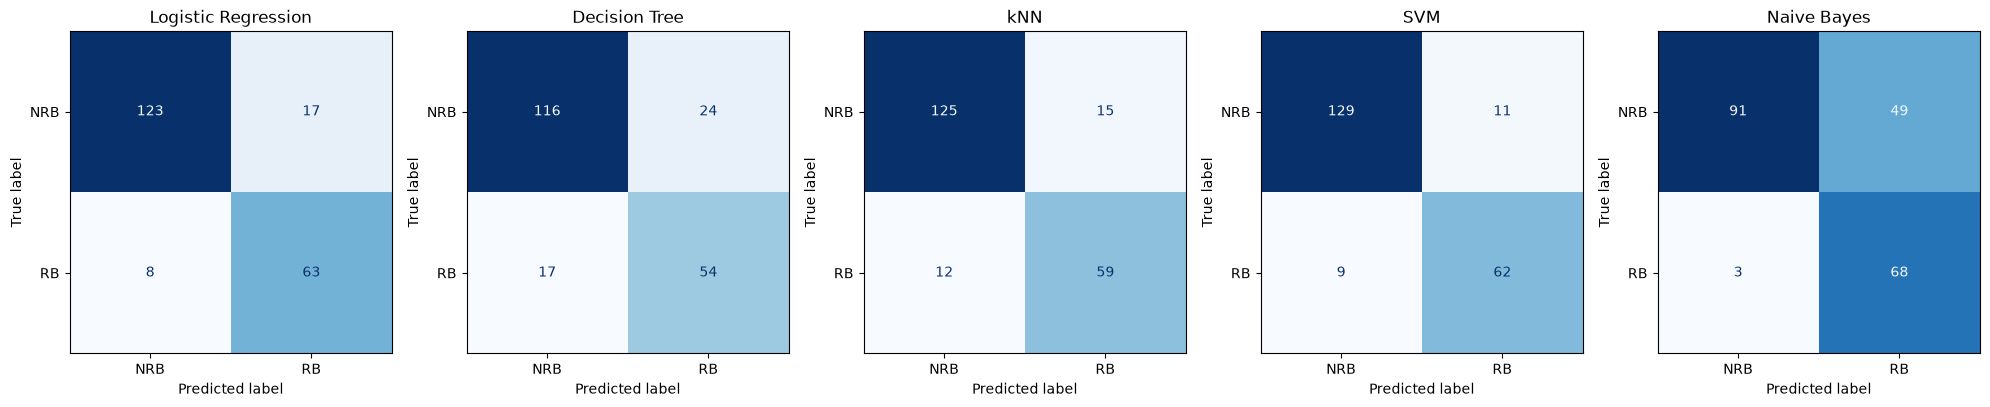

In [24]:
# Confusion matrix of each model on test data
# Rows = actual class, Columns = predicted class (0 = NRB, 1 = RB)
fig, axes = plt.subplots(1, len(test_predictions), figsize=(20, 4))

for ax, (model_name, y_pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["NRB", "RB"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

#### Observations: Test results

- **SVM is the best model.** It is on top in 5 of the 6 metrics (Accuracy 0.9052, AUC 0.9474, Precision 0.8493, F1 0.8611, MCC 0.7894). It made only 20 mistakes out of 211 molecules (11 NRB called RB, 9 RB missed).
- Logistic Regression is second (F1 0.8344, MCC 0.7459) and kNN is third (F1 0.8138, MCC 0.7167).
- Test F1 is close to CV F1 for every model (within about 0.04), and the order of the models is the same as in CV. So the CV scores were a good guide.
- Naive Bayes finds almost every RB molecule (Recall 0.9577, only 3 missed), but it also calls 49 NRB molecules RB (Precision 0.5812). So it says "RB" too easily. Its AUC is still high (0.9110), which means it ranks the molecules quite well, but the default cut-off (0.5) does not suit it.
- Decision Tree and Naive Bayes are the two weakest models (F1 about 0.72, MCC about 0.58). The Decision Tree also has the lowest AUC (0.8243).
- Accuracy alone can hide problems: every model is above 0.75 accuracy, but F1 and MCC show the gaps much more clearly.

---
---
### Saving Model

In [29]:
# Ensure that the model directory exists
Path("model").mkdir(parents=True, exist_ok=True)

# Saving all models in model directory
for model_name, model in best_models.items():
    # model name will be lowercase without space
    joblib.dump(model, f"model/{model_name.lower().replace(" ", "_")}.pkl")